# Lab Assignment 8: Motion Analysis
**Course:** Computer Vision and Image Processing (CSCS111/CSDS119)  
**Input Video:** `motion_corridor.avi`  
**Objective:** Analyse corridor surveillance footage to identify moving regions using frame differencing and MOG2 background subtraction, compare threshold settings, and investigate motion detection failure modes.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Load Video and Display Selected Consecutive Frames
- Load `motion_corridor.avi` using `cv2.VideoCapture`
- Print video metadata: total frame count, FPS, and frame resolution
- Convert frames to grayscale and observe consecutive frame differences

Video Metadata:
 - Total Frames : 96
 - FPS          : 12.0
 - Resolution   : 640 x 360


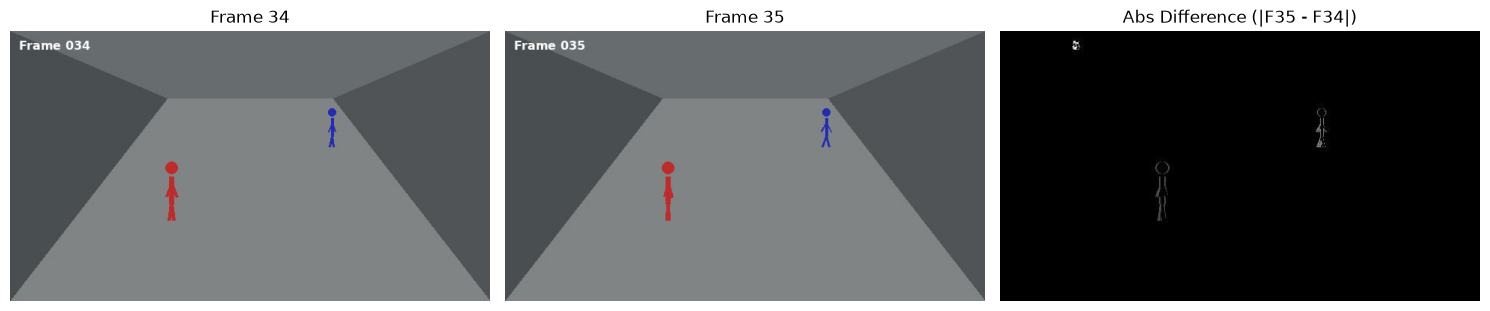

In [2]:
# Load video and retrieve metadata
video_path = 'motion_corridor.avi'
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise IOError(f"Cannot open video file: {video_path}")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("Video Metadata:")
print(f" - Total Frames : {total_frames}")
print(f" - FPS          : {fps}")
print(f" - Resolution   : {width} x {height}")

# Read all frames into memory
frames = []
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(frame)
cap.release()

# Convert frames to grayscale
gray_frames = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in frames]

# Display consecutive frames and absolute intensity difference
f1_idx, f2_idx = 34, 35
diff_sample = cv2.absdiff(gray_frames[f2_idx], gray_frames[f1_idx])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(cv2.cvtColor(frames[f1_idx], cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Frame {f1_idx}")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(frames[f2_idx], cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Frame {f2_idx}")
axes[1].axis('off')

axes[2].imshow(diff_sample, cmap='gray')
axes[2].set_title(f"Abs Difference (|F{f2_idx} - F{f1_idx}|)")
axes[2].axis('off')

plt.tight_layout()
plt.show()

## 2. Frame Differencing & Background Subtraction (MOG2) with Threshold Comparison
- **Frame Differencing:** Calculate $|I_t - I_{t-1}|$ and apply binary thresholding
- **Threshold Sensitivity:** Compare low ($T=15$), medium ($T=30$), and high ($T=60$) thresholds
- **MOG2 Background Subtractor:** Use `cv2.createBackgroundSubtractorMOG2()` to generate foreground masks

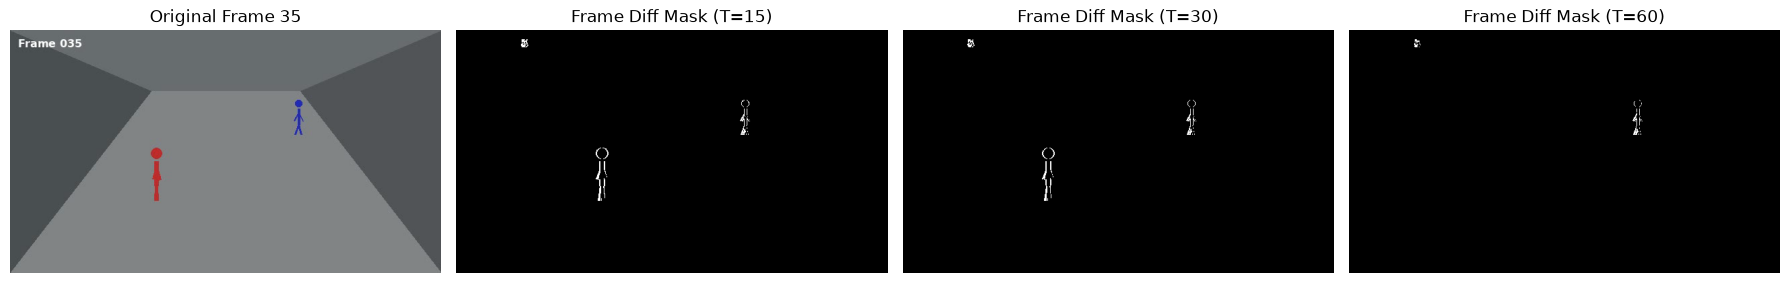

In [5]:
# Frame Differencing function with binary thresholding
def frame_difference_mask(prev_gray, curr_gray, threshold_val=30):
    diff = cv2.absdiff(curr_gray, prev_gray)
    _, mask = cv2.threshold(diff, threshold_val, 255, cv2.THRESH_BINARY)
    return diff, mask

# Compare effect of threshold settings on detected motion regions (Frame 35)
thresholds = [15, 30, 60]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

axes[0].imshow(cv2.cvtColor(frames[35], cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Frame 35")
axes[0].axis('off')

for idx, t in enumerate(thresholds):
    _, mask = frame_difference_mask(gray_frames[34], gray_frames[35], threshold_val=t)
    axes[idx + 1].imshow(mask, cmap='gray')
    axes[idx + 1].set_title(f"Frame Diff Mask (T={t})")
    axes[idx + 1].axis('off')

plt.tight_layout()
plt.show()

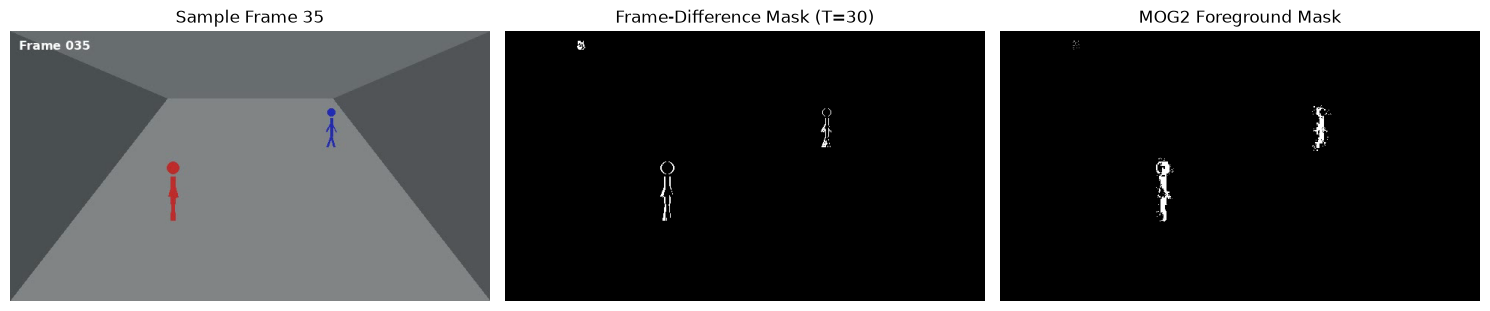

In [6]:
# MOG2 Background Subtraction
fgbg = cv2.createBackgroundSubtractorMOG2(history=50, varThreshold=25, detectShadows=True)

mog2_masks = []
for frame in frames:
    fg_mask = fgbg.apply(frame)
    mog2_masks.append(fg_mask)

# Display Frame, Frame-Difference Mask, and MOG2 Mask side-by-side
sample_idx = 35
_, fd_mask_sample = frame_difference_mask(gray_frames[sample_idx-1], gray_frames[sample_idx], threshold_val=30)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(cv2.cvtColor(frames[sample_idx], cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Sample Frame {sample_idx}")
axes[0].axis('off')

axes[1].imshow(fd_mask_sample, cmap='gray')
axes[1].set_title("Frame-Difference Mask (T=30)")
axes[1].axis('off')

axes[2].imshow(mog2_masks[sample_idx], cmap='gray')
axes[2].set_title("MOG2 Foreground Mask")
axes[2].axis('off')

plt.tight_layout()
plt.show()

## 3. Compare Methods on Paused Motion & Illumination Change
- **Segment 1 (Frame 62):** One of the persons stops moving.
- **Segment 2 (Frame 70):** Illumination changes abruptly across the corridor.
- We observe how Frame Differencing and MOG2 Background Subtraction respond.

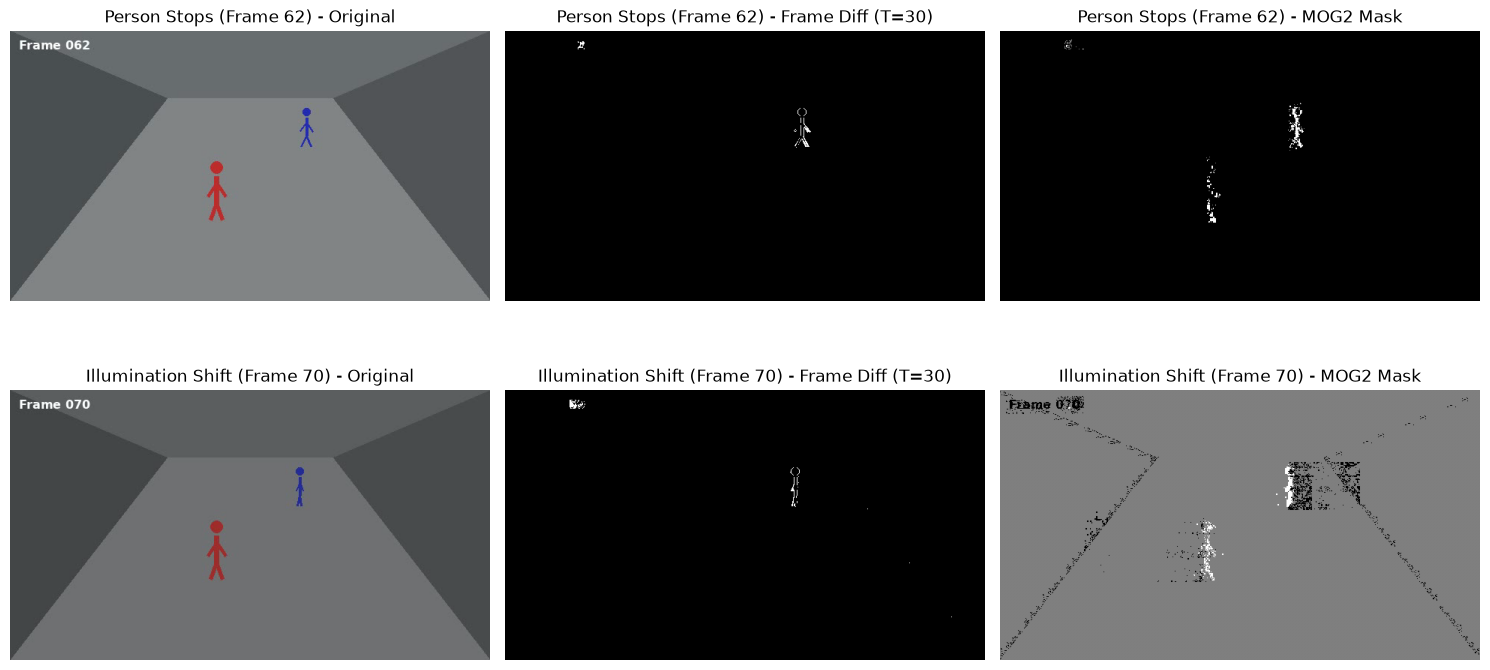

In [7]:
test_frames = [62, 70]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for row, f_idx in enumerate(test_frames):
    _, fd_m = frame_difference_mask(gray_frames[f_idx-1], gray_frames[f_idx], threshold_val=30)
    label = "Person Stops (Frame 62)" if f_idx == 62 else "Illumination Shift (Frame 70)"
    
    axes[row, 0].imshow(cv2.cvtColor(frames[f_idx], cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title(f"{label} - Original")
    axes[row, 0].axis('off')
    
    axes[row, 1].imshow(fd_m, cmap='gray')
    axes[row, 1].set_title(f"{label} - Frame Diff (T=30)")
    axes[row, 1].axis('off')
    
    axes[row, 2].imshow(mog2_masks[f_idx], cmap='gray')
    axes[row, 2].set_title(f"{label} - MOG2 Mask")
    axes[row, 2].axis('off')

plt.tight_layout()
plt.show()

## 4. Challenge & Discussion

### **Can a motion detector distinguish a stationary person from the background?**
**Answer:** **No**, standard pixel-level motion detectors cannot distinguish a stationary person from the background without higher-level object persistence or semantic recognition.

### **Limitations Evidenced in the Video:**
1. **Frame Differencing Limitation:**
   - Frame differencing strictly computes $|I_t - I_{t-1}|$.
   - At **Frame 60–65**, when one person stops walking, their inter-frame pixel difference drops to near zero.
   - The stationary person completely disappears from the motion mask immediately, causing false negatives.

2. **Background Subtraction (MOG2) Limitation:**
   - MOG2 continuously updates Gaussian distribution parameters to model the background.
   - While it detects the person right after they pause, continuing to remain static causes MOG2 to gradually absorb the person into the background model, after which they disappear.

3. **Illumination Variations:**
   - At **Frame 70**, an abrupt lighting shift alters pixel intensities globally across walls and floor.
   - Both frame differencing and background subtraction produce massive false positives across the entire frame.

### **Suggested Improvements:**
1. **Object Tracking & State Memory:** Pair motion detection with an object tracking algorithm (e.g., Kalman Filter, centroid tracking, or SORT). When a tracked moving bounding box stops moving, mark its state as "stationary object" rather than deleting it.
2. **Semantic / Deep Learning Detectors:** Use object detection models (e.g., YOLOv8, SSD) that identify persons based on visual feature representations (head, torso, limbs) regardless of whether they are in motion.
3. **Illumination Invariance:** Use normalized color spaces (e.g., chromaticity, HSV, or gradient/edge-based representations) or dynamic threshold adaptation to discard uniform global illumination shifts.